### EN3160 Assignment 3 on on Neural Networks

#### Index Number: 230724E
#### Name: Wijesekara WAGS

---

##### Github Link:  https://github.com/SathsaraGeeth/_vision_a03_.git

/home/geeth/miniconda3/envs/yolov13/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Epoch 1/20, Loss: 0.9769
Epoch 2/20, Loss: 0.9498
Epoch 3/20, Loss: 0.9361
Epoch 4/20, Loss: 0.9275
Epoch 5/20, Loss: 0.9216
Epoch 6/20, Loss: 0.9172
Epoch 7/20, Loss: 0.9138
Epoch 8/20, Loss: 0.9110
Epoch 9/20, Loss: 0.9088
Epoch 10/20, Loss: 0.9070
Epoch 11/20, Loss: 0.9054
Epoch 12/20, Loss: 0.9041
Epoch 13/20, Loss: 0.9029
Epoch 14/20, Loss: 0.9020
Epoch 15/20, Loss: 0.9011
Epoch 16/20, Loss: 0.9004
Epoch 17/20, Loss: 0.8997
Epoch 18/20, Loss: 0.8991
Epoch 19/20, Loss: 0.8986
Epoch 20/20, Loss: 0.8982


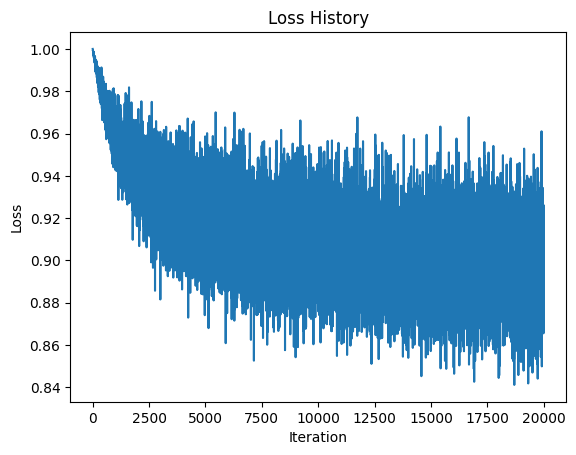

Training accuracy: 32.20%
Test accuracy: 32.40%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image)
K = 10             # Number of classes
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6
lr_decay = 0.9
reg = 0

loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):

        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]

        # Flatten input to (Ntr, Din)
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot vectors
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (Mean Squared Error + regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (manual gradients)
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)

        # dw = x_train.t().mm(dy_pred) + reg * w
        dw = x_train.t().mm(dy_pred) + 2 * reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )

    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():

    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        y_train_pred = x_train.mm(w) + b

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)

        correct_train += (
            predicted_train == labels
        ).sum().item()

train_acc = 100 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():

    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        y_test_pred = x_test.mm(w) + b

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)

        correct_test += (
            predicted_test == labels
        ).sum().item()

test_acc = 100 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")